# EDA 2 — ¿Los datos tienen estructura y sentido?

**Objetivo.** Evaluar si el dataset `dataset_dummy.xlsx` (10,000 clientes de tarjetas) es apto para análisis multivariado.
El notebook argumenta dos tesis con evidencia estadística:

1. **Las variables no se relacionan entre sí.** Correlaciones ≈ 0, pruebas de independencia no significativas y una matriz de correlación indistinguible de la identidad (Bartlett, KMO, PCA).
2. **Varios registros no tienen sentido de negocio.** Segmentos que no se reflejan en el ingreso, gasto mayor al ingreso, antigüedades imposibles, métricas de satisfacción contradictorias y distribuciones uniformes artificiales.

**Paleta.** Gris = contexto · Azul = variable principal · Naranja = anomalías · Verde y morado = grupos comparativos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter
from scipy import stats

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Paleta del equipo
GRIS, AZUL, NARANJA, VERDE, MORADO = "#7F7F7F", "#1F77B4", "#FF7F0E", "#2CA02C", "#9467BD"
FONDO, TINTA, TINTA2, REJILLA, NEUTRO = "#FFFFFF", "#222222", "#555555", "#E6E6E6", "#F2F2F2"
CMAP_DIV = LinearSegmentedColormap.from_list("div", [AZUL, NEUTRO, NARANJA])        # −1 azul · 0 neutro · +1 naranja
CMAP_SEQ = LinearSegmentedColormap.from_list("seq", [NEUTRO, "#9CC3E4", AZUL, "#0B3D66"])
COLOR_SEGMENTO = {"Mass": AZUL, "Premier": VERDE, "Select": MORADO}
MILES = FuncFormatter(lambda v, _: f"{v/1000:,.0f}k")

plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA2, "axes.titlecolor": TINTA,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left", "axes.labelsize": 10,
    "xtick.color": TINTA2, "ytick.color": TINTA2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.7, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "legend.fontsize": 9, "figure.dpi": 110,
})

In [2]:
df = pd.read_excel("dataset_dummy.xlsx")
num = df.select_dtypes("number")
cols = num.columns
N, p = num.shape
print(f"{df.shape[0]:,} filas × {df.shape[1]} columnas  |  {p} variables numéricas")
print("Nulos totales:", df.isna().sum().sum(), "| Filas duplicadas (sin customer_id):", df.drop(columns="customer_id").duplicated().sum())
df.head()

10,000 filas × 16 columnas  |  13 variables numéricas
Nulos totales: 0 | Filas duplicadas (sin customer_id): 0


,customer_id,edad,segmento,antiguedad_meses,ingreso_mensual,tarjeta_santander,uso_tarjeta_pct,transacciones_mes,gasto_mensual,ecommerce_pct,pagos_puntuales_pct,app_logins_mes,nps,satisfaccion,abandono_riesgo,activacion_promos_pct
0,C000001,56,Mass,15,"37,191.830",LikeU,15.600,19,"22,273.760",97.000,95.000,7,4,3.500,0.610,0.700
1,C000002,42,Premier,59,"20,621.540",Fiesta Rewards Platinum,23.300,11,"10,338.860",98.300,84.000,9,8,4.900,0.810,30.500
2,C000003,70,Mass,92,"16,142.710",Aeromexico Blanca,3.400,25,"10,096.710",31.200,85.600,10,1,4.100,0.940,89.500
3,C000004,31,Mass,15,"25,391.660",Free,27.100,23,"9,359.370",54.300,74.200,13,6,2.700,0.390,29.300
4,C000005,28,Mass,136,"42,073.200",LikeU,35.800,20,"15,932.130",31.100,79.800,12,10,3.200,0.380,97.200


---
## 1. Correlaciones entre las 13 variables numéricas

La escala va de −1 (azul) a +1 (naranja). En un dataset real de clientes esperaríamos bloques claros:
ingreso ↔ gasto, NPS ↔ satisfacción y satisfacción ↔ riesgo de abandono.

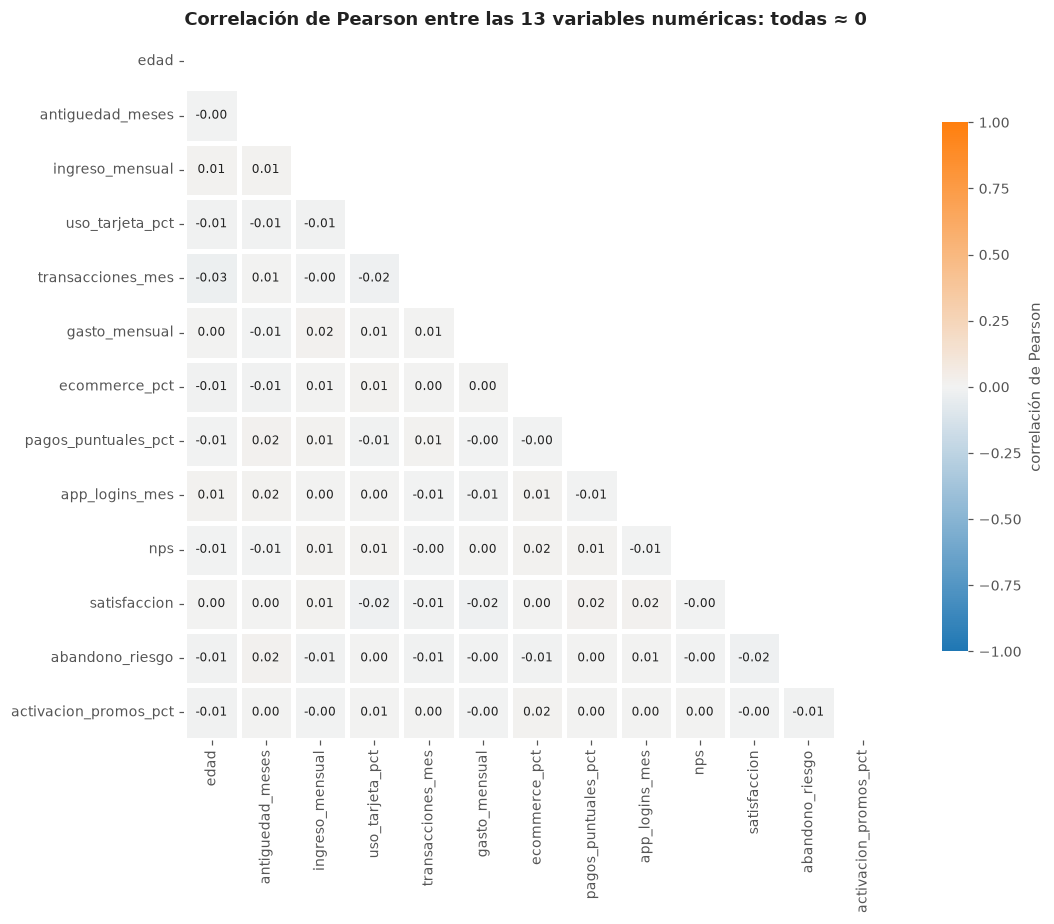

Máxima |r| de Pearson:   0.028  (edad vs transacciones_mes)
Máxima |ρ| de Spearman:  0.025  (descarta relaciones monótonas no lineales)


In [3]:
pearson = num.corr(method="pearson")
spearman = num.corr(method="spearman")

fig, ax = plt.subplots(figsize=(11, 8.5))
mask = np.triu(np.ones_like(pearson, dtype=bool))
sns.heatmap(pearson, mask=mask, vmin=-1, vmax=1, cmap=CMAP_DIV, annot=True, fmt=".2f",
            annot_kws={"size": 8, "color": TINTA}, linewidths=2, linecolor=FONDO, square=True,
            cbar_kws={"shrink": 0.75, "label": "correlación de Pearson"}, ax=ax)
ax.set_title("Correlación de Pearson entre las 13 variables numéricas: todas ≈ 0")
ax.grid(False)
plt.tight_layout(); plt.show()

fuera = ~np.eye(p, dtype=bool)
i, j = np.unravel_index(np.nanargmax(pearson.where(fuera).abs().values), (p, p))
print(f"Máxima |r| de Pearson:   {abs(pearson.values[i, j]):.3f}  ({cols[i]} vs {cols[j]})")
print(f"Máxima |ρ| de Spearman:  {spearman.where(fuera).abs().max().max():.3f}  (descarta relaciones monótonas no lineales)")

> **Lectura.** Todas las celdas son prácticamente neutras: **ningún par supera |r| = 0.03**. Spearman da el mismo resultado,
> así que tampoco hay relaciones monótonas ocultas.

## 2. Ingreso mensual por tarjeta

Cada tarjeta pertenece a un solo segmento (Mass, Premier o Select). Si la segmentación tuviera sentido,
las tarjetas premium deberían concentrar clientes de mayor ingreso.

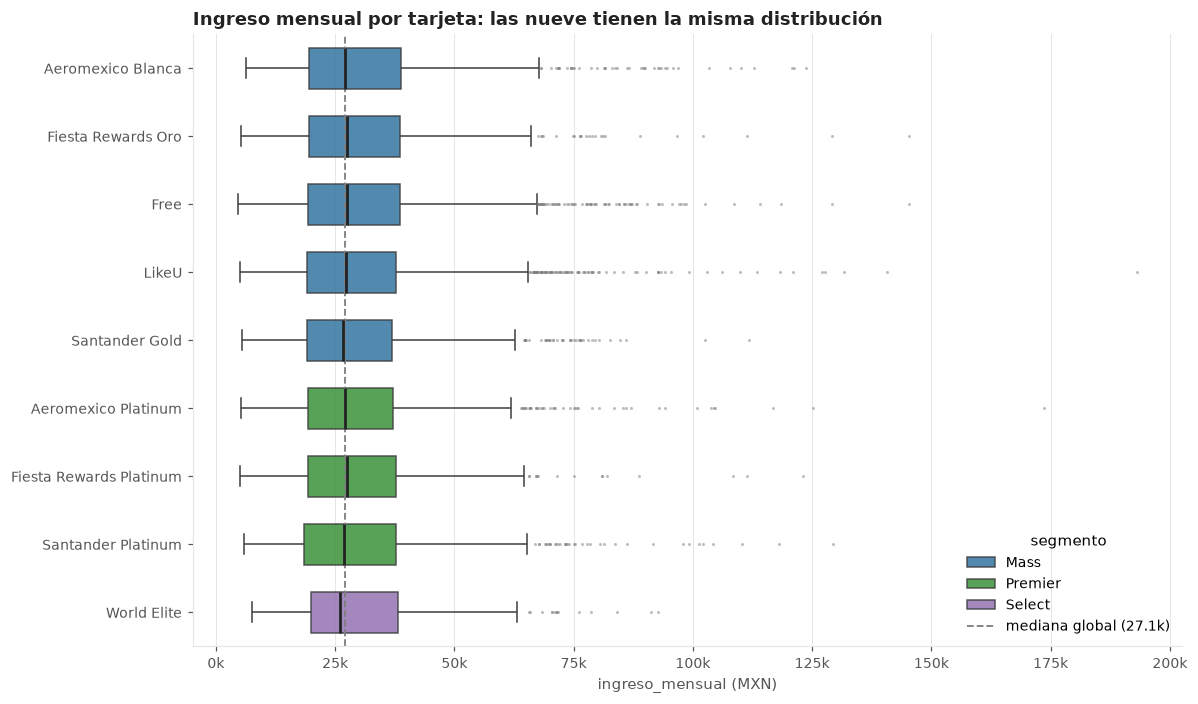

,segmento,clientes,ingreso_mediano,ingreso_mínimo,gasto_mediano
tarjeta_santander,,,,,
Aeromexico Blanca,Mass,1178,"27,029.430","6,243.680","11,110.305"
Fiesta Rewards Oro,Mass,686,"27,393.880","5,273.070","10,619.905"
Free,Mass,1998,"27,433.975","4,600.650","11,057.825"
LikeU,Mass,2512,"27,314.340","5,118.620","11,293.315"
Santander Gold,Mass,1000,"26,636.990","5,440.080","11,183.960"
Aeromexico Platinum,Premier,813,"27,108.870","5,203.920","11,004.430"
Fiesta Rewards Platinum,Premier,520,"27,520.260","4,967.630","10,856.800"
Santander Platinum,Premier,991,"26,936.840","5,796.880","11,292.800"
World Elite,Select,302,"26,019.240","7,680.780","10,694.235"


In [4]:
seg_tarjeta = df.groupby("tarjeta_santander")["segmento"].first()
orden = seg_tarjeta.map({"Mass": 0, "Premier": 1, "Select": 2}).sort_values(kind="stable").index.tolist()

fig, ax = plt.subplots(figsize=(11, 6.5))
sns.boxplot(data=df, y="tarjeta_santander", x="ingreso_mensual", order=orden, hue="segmento",
            palette=COLOR_SEGMENTO, dodge=False, width=0.6, fliersize=2, linewidth=1,
            boxprops={"alpha": 0.85}, medianprops={"color": TINTA, "linewidth": 1.8},
            flierprops={"marker": "o", "markerfacecolor": GRIS, "markeredgecolor": "none", "alpha": 0.5}, ax=ax)
mediana_global = df["ingreso_mensual"].median()
ax.axvline(mediana_global, color=GRIS, ls="--", lw=1.2, label=f"mediana global ({mediana_global/1000:,.1f}k)")
ax.xaxis.set_major_formatter(MILES)
ax.set_xlabel("ingreso_mensual (MXN)"); ax.set_ylabel("")
ax.set_title("Ingreso mensual por tarjeta: las nueve tienen la misma distribución")
ax.legend(title="segmento", loc="lower right")
plt.tight_layout(); plt.show()

(df.groupby("tarjeta_santander")
   .agg(segmento=("segmento", "first"), clientes=("customer_id", "size"),
        ingreso_mediano=("ingreso_mensual", "median"), ingreso_mínimo=("ingreso_mensual", "min"),
        gasto_mediano=("gasto_mensual", "median"))
   .loc[orden])

In [5]:
def kruskal_tabla(grupo):
    k = df[grupo].nunique()
    filas = []
    for c in cols:
        H, pv = stats.kruskal(*[g[c].values for _, g in df.groupby(grupo)])
        filas.append((c, H, pv, max((H - k + 1) / (N - k), 0)))
    return pd.DataFrame(filas, columns=["variable", "H", "p_valor", "épsilon²"]).set_index("variable")

kw = pd.concat({"segmento": kruskal_tabla("segmento"), "tarjeta": kruskal_tabla("tarjeta_santander")}, axis=1)
print("Variables que difieren significativamente (p<0.05):",
      (kw[("segmento", "p_valor")] < 0.05).sum(), "por segmento |",
      (kw[("tarjeta", "p_valor")] < 0.05).sum(), "por tarjeta")
kw

Variables que difieren significativamente (p<0.05): 0 por segmento | 0 por tarjeta


segmento                  tarjeta                 
                             H p_valor épsilon²       H p_valor épsilon²
variable                                                                
edad                     0.277   0.871    0.000   1.829   0.986    0.000
antiguedad_meses         0.934   0.627    0.000  12.005   0.151    0.000
ingreso_mensual          0.883   0.643    0.000   5.736   0.677    0.000
uso_tarjeta_pct          1.832   0.400    0.000  12.390   0.135    0.000
transacciones_mes        1.861   0.394    0.000   9.587   0.295    0.000
gasto_mensual            1.764   0.414    0.000   5.041   0.753    0.000
ecommerce_pct            0.319   0.853    0.000   8.018   0.432    0.000
pagos_puntuales_pct      0.158   0.924    0.000  10.704   0.219    0.000
app_logins_mes           1.786   0.409    0.000   2.726   0.950    0.000
nps                      0.174   0.917    0.000   5.376   0.717    0.000
satisfaccion             3.389   0.184    0.000   8.518   0.385    0.000
abandono_riesgo          1.571   0.456    0.000   5.046   0.753    0.000
activacion_promos_pct    2.984   0.225    0.000   8.951   0.346    0.000

> **Lectura.** World Elite, la única tarjeta del segmento Select, tiene una mediana de ingreso **menor** que la tarjeta Free.
> Kruskal-Wallis confirma que **ninguna de las 13 variables** cambia por segmento ni por tarjeta (ε² ≈ 0). Las categorías no segmentan nada.

---
## 3. Prueba multivariada formal: ¿hay algo que reducir o factorizar?

* **Esfericidad de Bartlett.** H₀: la matriz de correlación es la identidad, es decir, las variables no están correlacionadas.
* **KMO (Kaiser-Meyer-Olkin).** Menos de 0.5 es inaceptable, alrededor de 0.5 es miserable y más de 0.7 es aceptable.
* **Scree plot con análisis paralelo de Horn.** Compara los eigenvalores reales contra los de datos 100 % aleatorios del mismo tamaño.

In [6]:
R = pearson.values
triu = np.triu_indices(p, 1)

chi2_b = -(N - 1 - (2 * p + 5) / 6) * np.log(np.linalg.det(R))
gl_b = p * (p - 1) / 2
p_b = stats.chi2.sf(chi2_b, gl_b)

R_inv = np.linalg.inv(R)
parcial = -R_inv / np.sqrt(np.outer(np.diag(R_inv), np.diag(R_inv)))
kmo = (R[triu] ** 2).sum() / ((R[triu] ** 2).sum() + (parcial[triu] ** 2).sum())

print(f"Bartlett: χ² = {chi2_b:.2f}, gl = {gl_b:.0f}, p = {p_b:.3f}  →  {'NO se rechaza' if p_b > 0.05 else 'se rechaza'} H₀ (matriz identidad)")
print(f"KMO global = {kmo:.3f}  →  {'inaceptable / miserable' if kmo < 0.6 else 'aceptable'} para análisis factorial")

Bartlett: χ² = 81.17, gl = 78, p = 0.381  →  NO se rechaza H₀ (matriz identidad)
KMO global = 0.502  →  inaceptable / miserable para análisis factorial


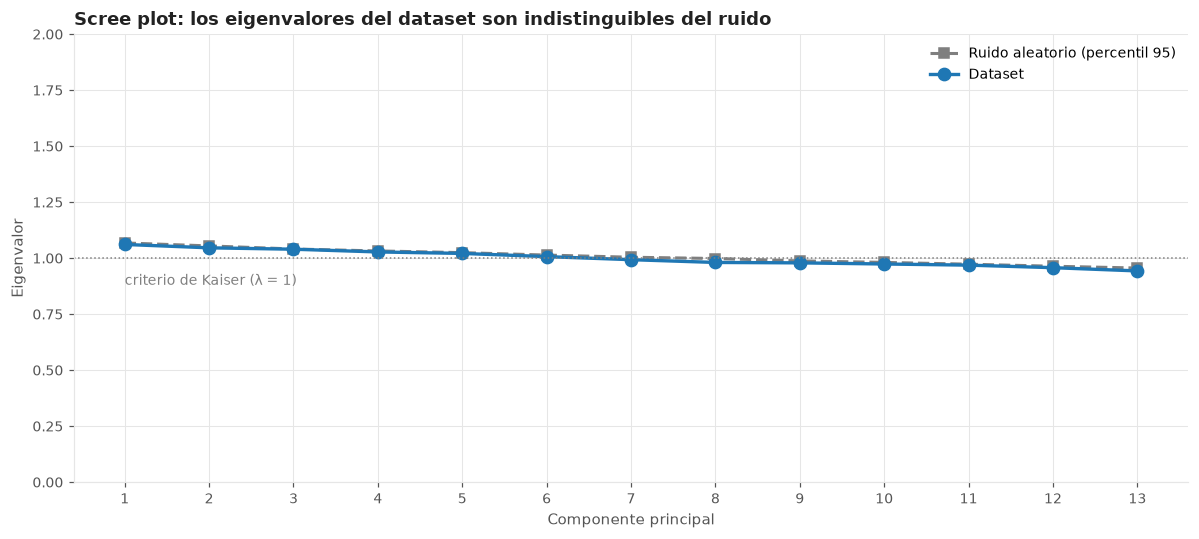

PC1 explica 8.2% de la varianza (si todo fuera independiente: 1/13 = 7.7%)
Se necesitan 11 de 13 componentes para explicar el 80 %
Componentes que superan al ruido (análisis paralelo): 0


In [7]:
eig = np.sort(np.linalg.eigvalsh(R))[::-1]
var_exp = eig / eig.sum()
rng = np.random.default_rng(42)
sim = np.array([np.sort(np.linalg.eigvalsh(np.corrcoef(rng.standard_normal((N, p)), rowvar=False)))[::-1] for _ in range(50)])
ref95 = np.percentile(sim, 95, axis=0)

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(1, p + 1)
ax.plot(x, ref95, marker="s", color=GRIS, lw=2, ms=6, ls="--", label="Ruido aleatorio (percentil 95)")
ax.plot(x, eig, marker="o", color=AZUL, lw=2.2, ms=8, label="Dataset")
ax.axhline(1, color=GRIS, lw=1, ls=":")
ax.text(1, 0.93, "criterio de Kaiser (λ = 1)", ha="left", va="top", color=GRIS, fontsize=9)
ax.set_ylim(0, 2); ax.set_xticks(x)
ax.set_xlabel("Componente principal"); ax.set_ylabel("Eigenvalor")
ax.set_title("Scree plot: los eigenvalores del dataset son indistinguibles del ruido")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

print(f"PC1 explica {var_exp[0]:.1%} de la varianza (si todo fuera independiente: 1/{p} = {1/p:.1%})")
print(f"Se necesitan {np.searchsorted(np.cumsum(var_exp), 0.8) + 1} de {p} componentes para explicar el 80 %")
print(f"Componentes que superan al ruido (análisis paralelo): {(eig > ref95).sum()}")

> **Lectura.** No se rechaza la esfericidad de Bartlett, el KMO es ≈ 0.5 y la curva del dataset queda sobre (o por debajo de) la del ruido puro.
> **PCA y análisis factorial no tienen nada que extraer.**

## 4. Relaciones que *deberían* existir por lógica de negocio

Elegimos ocho pares con una relación obvia en clientes reales y medimos su correlación. Como referencia visual, las líneas
punteadas marcan una correlación moderada (|r| = 0.3) y la banda gris el rango despreciable (|r| < 0.1).

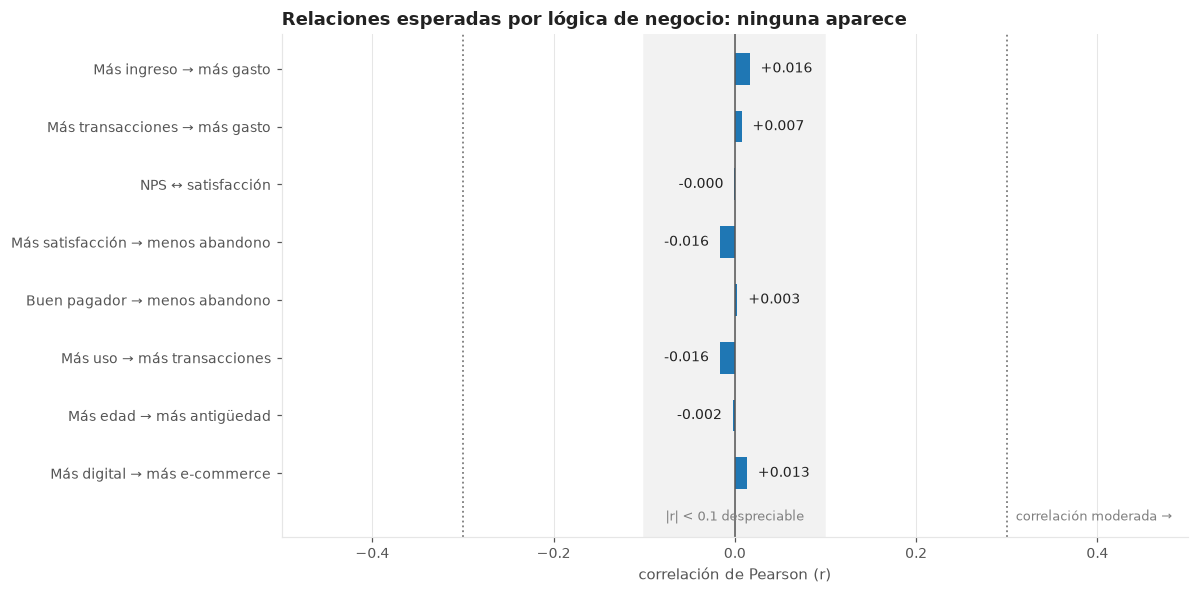

,hipótesis,r,p_valor
0,Más ingreso → más gasto,0.016,0.103
1,Más transacciones → más gasto,0.007,0.462
2,NPS ↔ satisfacción,-0.000,0.965
3,Más satisfacción → menos abandono,-0.016,0.101
4,Buen pagador → menos abandono,0.003,0.778
5,Más uso → más transacciones,-0.016,0.100
6,Más edad → más antigüedad,-0.002,0.825
7,Más digital → más e-commerce,0.013,0.183


In [8]:
pares_logicos = [
    ("ingreso_mensual", "gasto_mensual", "Más ingreso → más gasto"),
    ("transacciones_mes", "gasto_mensual", "Más transacciones → más gasto"),
    ("nps", "satisfaccion", "NPS ↔ satisfacción"),
    ("satisfaccion", "abandono_riesgo", "Más satisfacción → menos abandono"),
    ("pagos_puntuales_pct", "abandono_riesgo", "Buen pagador → menos abandono"),
    ("uso_tarjeta_pct", "transacciones_mes", "Más uso → más transacciones"),
    ("edad", "antiguedad_meses", "Más edad → más antigüedad"),
    ("app_logins_mes", "ecommerce_pct", "Más digital → más e-commerce"),
]
rel = pd.DataFrame([(h, df[a].corr(df[b]), stats.pearsonr(df[a], df[b])[1]) for a, b, h in pares_logicos],
                   columns=["hipótesis", "r", "p_valor"])

fig, ax = plt.subplots(figsize=(11, 5.5))
yy = np.arange(len(rel))[::-1]
ax.axvspan(-0.1, 0.1, color=NEUTRO, zorder=0)
for v in (-0.3, 0.3):
    ax.axvline(v, color=GRIS, ls=":", lw=1.2)
ax.text(0.31, -0.75, "correlación moderada →", color=GRIS, fontsize=8.5, va="center")
ax.text(0, -0.75, "|r| < 0.1 despreciable", color=GRIS, fontsize=8.5, va="center", ha="center")
ax.barh(yy, rel["r"], color=AZUL, height=0.55)
for y, r in zip(yy, rel["r"]):
    ax.text(r + (0.012 if r >= 0 else -0.012), y, f"{r:+.3f}", va="center", ha="left" if r >= 0 else "right", color=TINTA, fontsize=9)
ax.axvline(0, color=TINTA2, lw=1)
ax.set_yticks(yy, rel["hipótesis"]); ax.set_xlim(-0.5, 0.5); ax.set_ylim(-1.1, len(rel) - 0.4)
ax.set_xlabel("correlación de Pearson (r)")
ax.set_title("Relaciones esperadas por lógica de negocio: ninguna aparece")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
rel

---
## 5. Antigüedad imposible respecto a la edad

Una tarjeta de crédito requiere mayoría de edad, así que la antigüedad máxima posible es (edad − 18) × 12 meses.

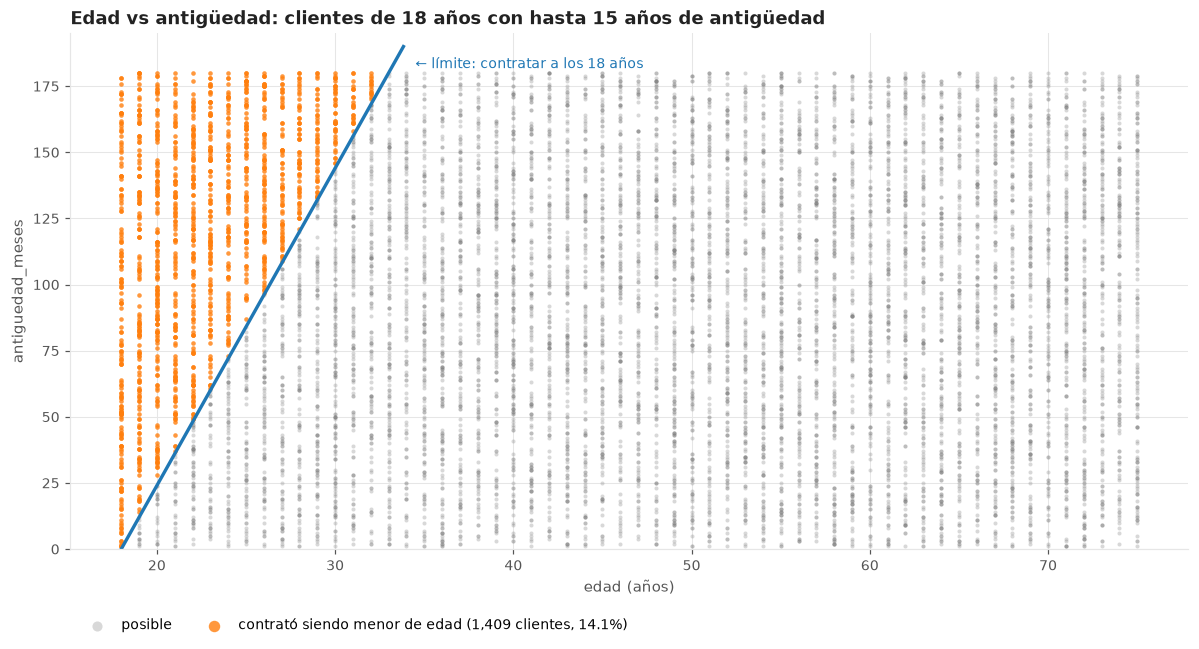

,customer_id,edad,antiguedad_meses,edad_al_contratar
8292,C008293,18,178,3.167
2857,C002858,18,178,3.167
6075,C006076,18,176,3.333
9407,C009408,18,173,3.583
4581,C004582,18,172,3.667
4620,C004621,18,172,3.667
6791,C006792,18,172,3.667
9854,C009855,18,170,3.833


In [9]:
df_chk = df.assign(
    ratio_gasto_ingreso=df.gasto_mensual / df.ingreso_mensual,
    edad_al_contratar=df.edad - df.antiguedad_meses / 12,
)
mal = df_chk.edad_al_contratar < 18

fig, ax = plt.subplots(figsize=(11, 6))
ax.scatter(df.edad[~mal], df.antiguedad_meses[~mal], s=7, color=GRIS, alpha=0.3, linewidths=0, label="posible")
ax.scatter(df.edad[mal], df.antiguedad_meses[mal], s=9, color=NARANJA, alpha=0.8, linewidths=0,
           label=f"contrató siendo menor de edad ({mal.sum():,} clientes, {mal.mean():.1%})")
e = np.linspace(18, 18 + 190 / 12, 50)
ax.plot(e, (e - 18) * 12, color=AZUL, lw=2.2)
ax.text(34.5, 186, "← límite: contratar a los 18 años", color=AZUL, fontsize=9, va="top")
ax.set_ylim(0, 195)
ax.set_xlabel("edad (años)"); ax.set_ylabel("antiguedad_meses")
ax.set_title("Edad vs antigüedad: clientes de 18 años con hasta 15 años de antigüedad")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.11), ncol=2, markerscale=2.5)
plt.tight_layout(); plt.show()
df_chk.loc[mal, ["customer_id", "edad", "antiguedad_meses", "edad_al_contratar"]].sort_values("edad_al_contratar").head(8)

> Hay clientes de 18 años con 178 meses de antigüedad, es decir, **habrían contratado la tarjeta a los 3 años**.
> La antigüedad se generó sin considerar la edad.

## 6. Gasto mayor al ingreso

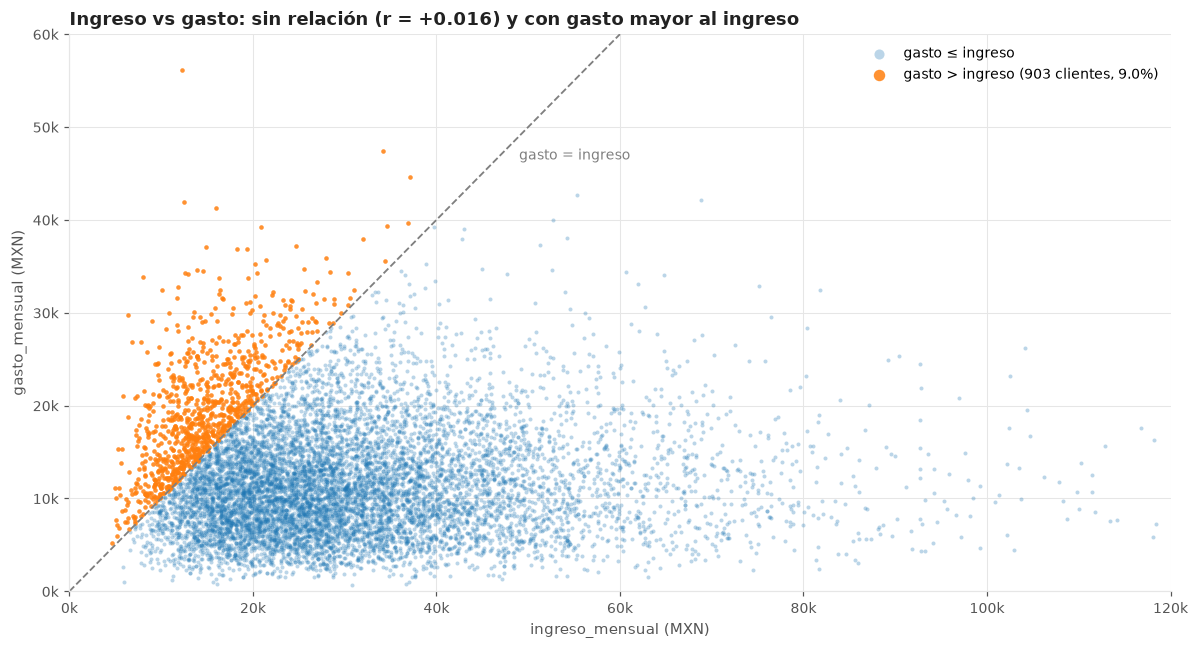

,customer_id,segmento,ingreso_mensual,gasto_mensual,ratio_gasto_ingreso
1315,C001316,Mass,"6,419.430","29,727.110",4.631
1274,C001275,Premier,"12,288.270","56,173.870",4.571
9273,C009274,Premier,"8,007.750","33,811.090",4.222
2037,C002038,Mass,"6,863.910","26,874.860",3.915
4916,C004917,Mass,"5,799.870","21,027.030",3.625
7177,C007178,Mass,"7,778.210","26,834.250",3.450
6720,C006721,Premier,"12,477.110","41,873.570",3.356
337,C000338,Mass,"8,994.540","29,156.690",3.242


In [10]:
excede = df_chk.ratio_gasto_ingreso > 1

fig, ax = plt.subplots(figsize=(11, 6))
ax.scatter(df.ingreso_mensual[~excede], df.gasto_mensual[~excede], s=7, color=AZUL, alpha=0.3, linewidths=0, label="gasto ≤ ingreso")
ax.scatter(df.ingreso_mensual[excede], df.gasto_mensual[excede], s=9, color=NARANJA, alpha=0.85, linewidths=0,
           label=f"gasto > ingreso ({excede.sum():,} clientes, {excede.mean():.1%})")
ax.plot([0, 60_000], [0, 60_000], color=GRIS, lw=1.2, ls="--")
ax.text(49_000, 46_500, "gasto = ingreso", color=GRIS, fontsize=9, ha="left")
ax.set_xlim(0, 120_000); ax.set_ylim(0, 60_000)
ax.xaxis.set_major_formatter(MILES); ax.yaxis.set_major_formatter(MILES)
ax.set_xlabel("ingreso_mensual (MXN)"); ax.set_ylabel("gasto_mensual (MXN)")
ax.set_title(f"Ingreso vs gasto: sin relación (r = {df.ingreso_mensual.corr(df.gasto_mensual):+.3f}) y con gasto mayor al ingreso")
ax.legend(loc="upper right", markerscale=2.5)
plt.tight_layout(); plt.show()
df_chk.loc[excede, ["customer_id", "segmento", "ingreso_mensual", "gasto_mensual", "ratio_gasto_ingreso"]].sort_values("ratio_gasto_ingreso", ascending=False).head(8)

> El gasto **no crece con el ingreso**: un cliente que gana $5,000 tiene la misma distribución de gasto que uno que gana $100,000.
> Por eso aparecen casos que gastan varias veces su ingreso mensual.

## 7. NPS y satisfacción se contradicen

NPS (0–10) y satisfacción (1–5) miden lo mismo desde dos escalas. Un promotor debería concentrarse en satisfacción alta.

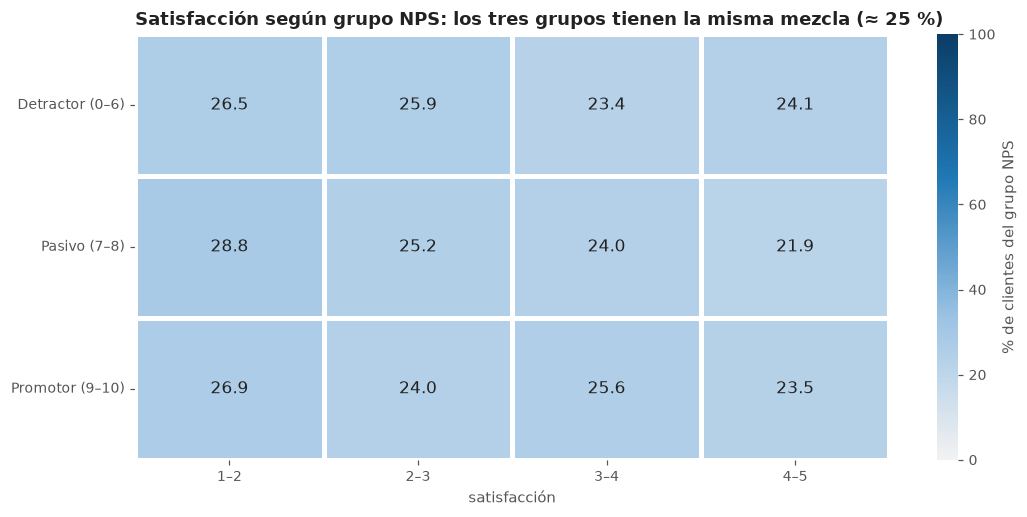

Promotores (NPS 9–10) con satisfacción ≤ 2: 496
Detractores (NPS 0–2) con satisfacción ≥ 4.5: 396
χ² de independencia NPS × satisfacción: p = 0.097


In [11]:
grupo_nps = pd.cut(df.nps, [-1, 6, 8, 10], labels=["Detractor (0–6)", "Pasivo (7–8)", "Promotor (9–10)"])
nivel_sat = pd.cut(df.satisfaccion, [0, 2, 3, 4, 5], labels=["1–2", "2–3", "3–4", "4–5"])
tab = pd.crosstab(grupo_nps, nivel_sat, normalize="index") * 100

fig, ax = plt.subplots(figsize=(10, 4.8))
sns.heatmap(tab, annot=True, fmt=".1f", cmap=CMAP_SEQ, vmin=0, vmax=100, linewidths=2, linecolor=FONDO,
            annot_kws={"color": TINTA, "size": 11}, cbar_kws={"label": "% de clientes del grupo NPS"}, ax=ax)
ax.set_title("Satisfacción según grupo NPS: los tres grupos tienen la misma mezcla (≈ 25 %)")
ax.set_xlabel("satisfacción"); ax.set_ylabel(""); ax.grid(False)
ax.tick_params(axis="y", rotation=0)
plt.tight_layout(); plt.show()

print("Promotores (NPS 9–10) con satisfacción ≤ 2:", ((df.nps >= 9) & (df.satisfaccion <= 2)).sum())
print("Detractores (NPS 0–2) con satisfacción ≥ 4.5:", ((df.nps <= 2) & (df.satisfaccion >= 4.5)).sum())
chi2_ns, p_ns, *_ = stats.chi2_contingency(pd.crosstab(grupo_nps, nivel_sat))
print(f"χ² de independencia NPS × satisfacción: p = {p_ns:.3f}")

## 8. El riesgo de abandono no depende de la satisfacción

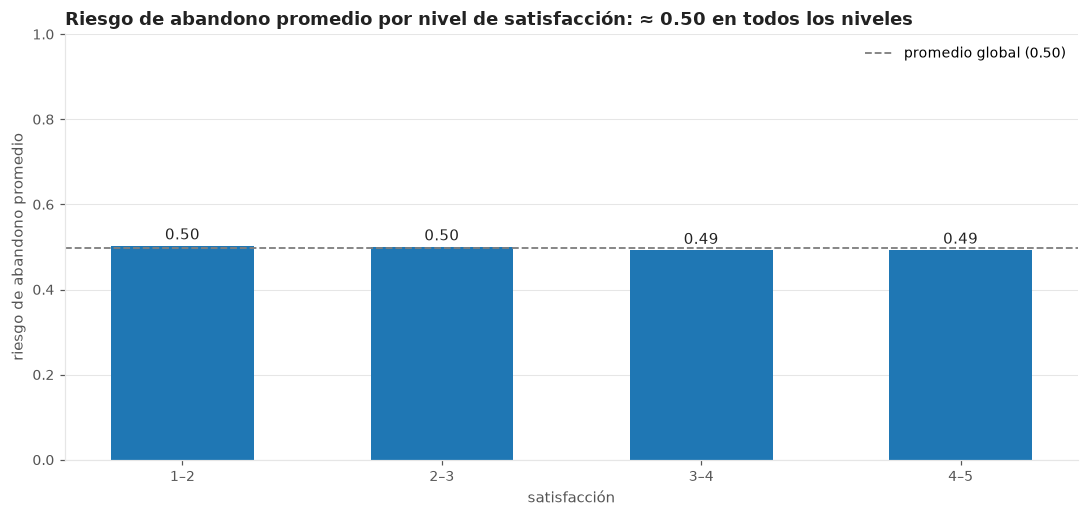

In [12]:
medias = df.groupby(nivel_sat, observed=True)["abandono_riesgo"].mean()

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(medias.index.astype(str), medias.values, color=AZUL, width=0.55)
for k, v in enumerate(medias.values):
    ax.text(k, v + 0.015, f"{v:.2f}", ha="center", color=TINTA, fontsize=10)
ax.axhline(df.abandono_riesgo.mean(), color=GRIS, ls="--", lw=1.2, label=f"promedio global ({df.abandono_riesgo.mean():.2f})")
ax.legend(loc="upper right")
ax.set_ylim(0, 1)
ax.set_xlabel("satisfacción"); ax.set_ylabel("riesgo de abandono promedio")
ax.set_title("Riesgo de abandono promedio por nivel de satisfacción: ≈ 0.50 en todos los niveles")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

> Un cliente muy satisfecho tiene el mismo riesgo de abandono que uno muy insatisfecho. **Cada métrica se generó por separado.**

---
## 9. Distribuciones artificialmente uniformes

En una cartera real la edad se concentra en adultos de mediana edad, el uso de la tarjeta tiene sesgo y el NPS se concentra en los extremos.
Aquí casi todas las variables son **uniformes**, el patrón típico de `random.uniform`.

Para verlo en una sola gráfica escalamos cada variable a [0, 1] y trazamos su **función de distribución acumulada empírica (ECDF)**.
Una variable uniforme cae exactamente sobre la diagonal. Como contraste incluimos `ingreso_mensual`, que no es uniforme.

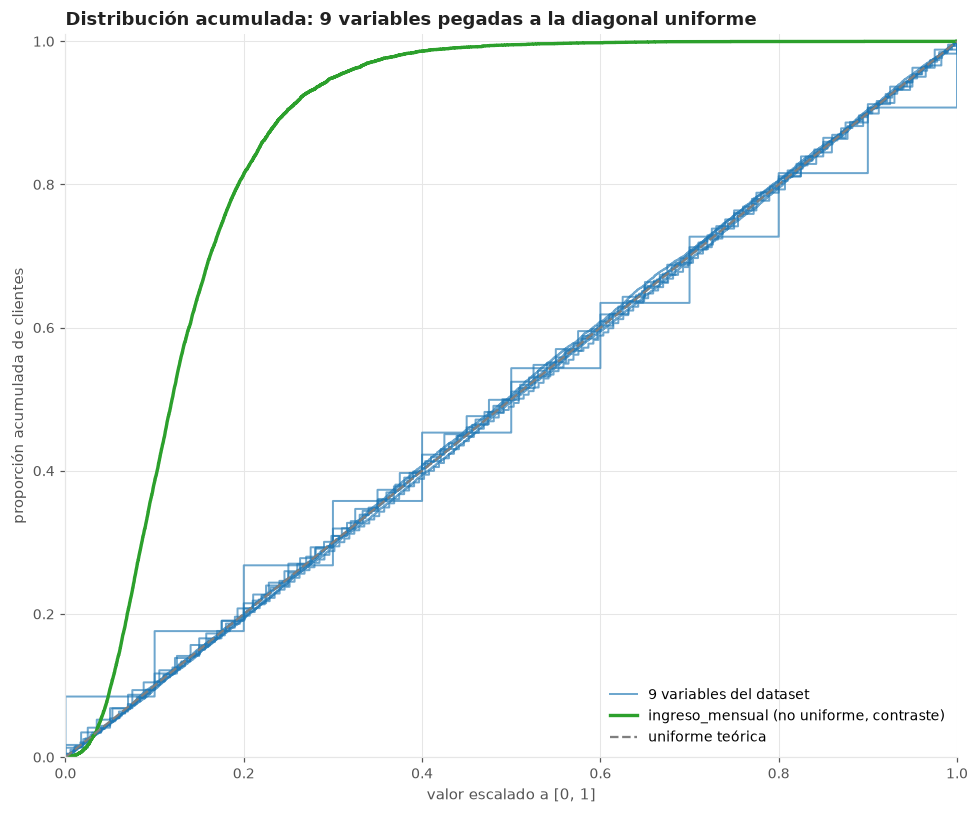

In [13]:
candidatas = ["edad", "antiguedad_meses", "uso_tarjeta_pct", "ecommerce_pct", "activacion_promos_pct",
              "pagos_puntuales_pct", "abandono_riesgo", "nps", "satisfaccion"]

def ecdf_escalada(s):
    z = np.sort((s - s.min()) / (s.max() - s.min()))
    return z, np.arange(1, len(z) + 1) / len(z)

fig, ax = plt.subplots(figsize=(9, 7.5))
for k, c in enumerate(candidatas):
    z, F = ecdf_escalada(df[c])
    ax.step(z, F, where="post", color=AZUL, lw=1.3, alpha=0.65, label="9 variables del dataset" if k == 0 else None)
z, F = ecdf_escalada(df["ingreso_mensual"])
ax.step(z, F, where="post", color=VERDE, lw=2.2, label="ingreso_mensual (no uniforme, contraste)")
ax.plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1.5, label="uniforme teórica")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.01)
ax.set_xlabel("valor escalado a [0, 1]"); ax.set_ylabel("proporción acumulada de clientes")
ax.set_title("Distribución acumulada: 9 variables pegadas a la diagonal uniforme")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

In [14]:
def prueba_uniforme(s):
    """χ² de bondad de ajuste contra una uniforme, respetando el redondeo de la columna."""
    a, b = s.min(), s.max()
    if pd.api.types.is_integer_dtype(s):
        valores = np.arange(a, b + 1)
        esperado = np.full(len(valores), len(s) / len(valores))
    else:
        dec = int(s.astype(str).str.split(".").str[1].str.len().max())
        h = 10 ** -dec
        valores = np.round(np.arange(a, b + h / 2, h), dec)
        ancho = np.minimum(valores + h / 2, b) - np.maximum(valores - h / 2, a)  # los extremos valen medio paso
        esperado = ancho / ancho.sum() * len(s)
    observado = s.round(6).value_counts().reindex(valores, fill_value=0).values
    return stats.chisquare(observado, esperado).pvalue

unif = pd.DataFrame({"mín": df[candidatas].min(), "máx": df[candidatas].max(),
                     "p_valor (H₀: uniforme)": [prueba_uniforme(df[c]) for c in candidatas]})
unif["¿compatible con uniforme?"] = np.where(unif["p_valor (H₀: uniforme)"] > 0.05, "Sí", "No (marginal)")
unif

,mín,máx,p_valor (H₀: uniforme),¿compatible con uniforme?
edad,18.000,75.000,0.820,Sí
antiguedad_meses,1.000,180.000,0.246,Sí
uso_tarjeta_pct,0.000,100.000,0.849,Sí
ecommerce_pct,0.000,100.000,0.119,Sí
activacion_promos_pct,0.000,100.000,0.924,Sí
pagos_puntuales_pct,70.000,100.000,0.917,Sí
abandono_riesgo,0.000,1.000,0.493,Sí
nps,0.000,10.000,0.628,Sí
satisfaccion,1.000,5.000,0.026,No (marginal)


> **Lectura.** Ocho de nueve variables son estadísticamente indistinguibles de una uniforme. Satisfacción es la única marginal
> (p ≈ 0.03), pero también queda pegada a la diagonal. Además, `pagos_puntuales_pct` tiene un piso exacto en 70 %:
> **ningún cliente paga a tiempo menos del 70 % de las veces**.

## 10. Resumen de reglas de negocio violadas

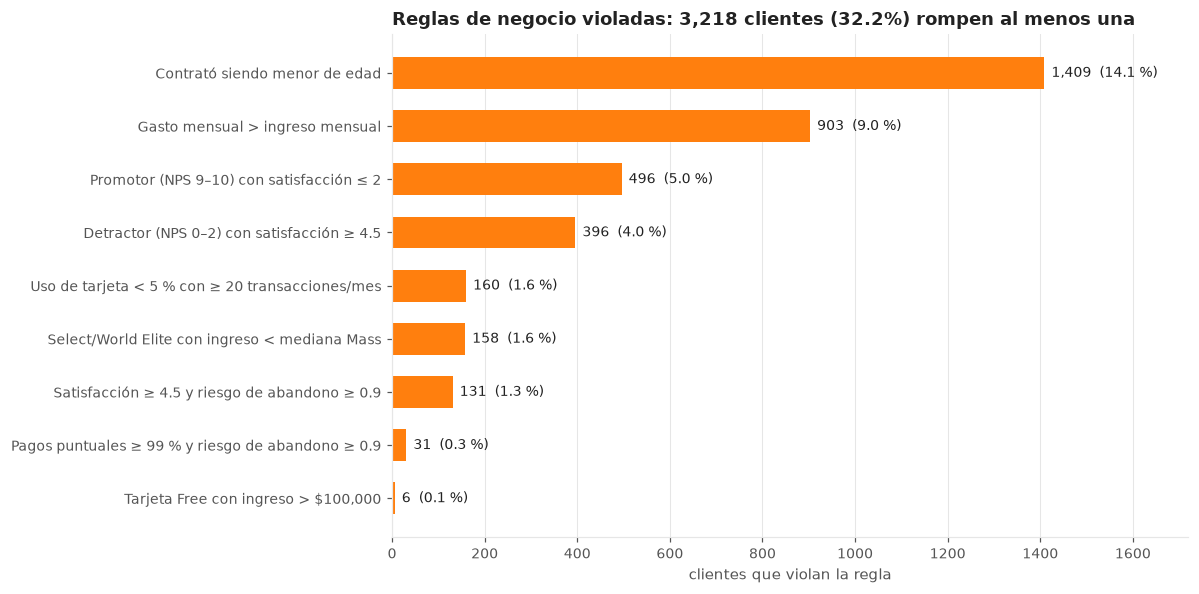

,registros,% del total
Contrató siendo menor de edad,1409,14.090
Gasto mensual > ingreso mensual,903,9.030
Promotor (NPS 9–10) con satisfacción ≤ 2,496,4.960
Detractor (NPS 0–2) con satisfacción ≥ 4.5,396,3.960
Uso de tarjeta < 5 % con ≥ 20 transacciones/mes,160,1.600
Select/World Elite con ingreso < mediana Mass,158,1.580
Satisfacción ≥ 4.5 y riesgo de abandono ≥ 0.9,131,1.310
Pagos puntuales ≥ 99 % y riesgo de abandono ≥ 0.9,31,0.310
"Tarjeta Free con ingreso > $100,000",6,0.060


In [15]:
mediana_ingreso_mass = df.loc[df.segmento == "Mass", "ingreso_mensual"].median()
reglas = {
    "Contrató siendo menor de edad": mal,
    "Gasto mensual > ingreso mensual": excede,
    "Promotor (NPS 9–10) con satisfacción ≤ 2": (df.nps >= 9) & (df.satisfaccion <= 2),
    "Detractor (NPS 0–2) con satisfacción ≥ 4.5": (df.nps <= 2) & (df.satisfaccion >= 4.5),
    "Uso de tarjeta < 5 % con ≥ 20 transacciones/mes": (df.uso_tarjeta_pct < 5) & (df.transacciones_mes >= 20),
    "Select/World Elite con ingreso < mediana Mass": (df.segmento == "Select") & (df.ingreso_mensual < mediana_ingreso_mass),
    "Satisfacción ≥ 4.5 y riesgo de abandono ≥ 0.9": (df.satisfaccion >= 4.5) & (df.abandono_riesgo >= 0.9),
    "Pagos puntuales ≥ 99 % y riesgo de abandono ≥ 0.9": (df.pagos_puntuales_pct >= 99) & (df.abandono_riesgo >= 0.9),
    "Tarjeta Free con ingreso > $100,000": (df.tarjeta_santander == "Free") & (df.ingreso_mensual > 100_000),
}
tabla_reglas = (pd.DataFrame({"registros": {k: int(v.sum()) for k, v in reglas.items()}})
                  .assign(**{"% del total": lambda t: t.registros / N * 100})
                  .sort_values("registros"))
cualquiera = np.logical_or.reduce(list(reglas.values()))

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.barh(tabla_reglas.index, tabla_reglas.registros, color=NARANJA, height=0.6)
for y, (n_reg, pct) in enumerate(zip(tabla_reglas.registros, tabla_reglas["% del total"])):
    ax.text(n_reg + 15, y, f"{n_reg:,}  ({pct:.1f} %)", va="center", color=TINTA, fontsize=9)
ax.set_xlim(0, tabla_reglas.registros.max() * 1.22)
ax.set_xlabel("clientes que violan la regla")
ax.set_title(f"Reglas de negocio violadas: {cualquiera.sum():,} clientes ({cualquiera.mean():.1%}) rompen al menos una")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
tabla_reglas.sort_values("registros", ascending=False)

---
## Anexo — Pruebas de significancia complementarias

### A.1 ¿Alguna correlación es significativa?
Con 78 pares y α = 0.05, si todo fuera ruido esperaríamos ≈ 3.9 falsos positivos por azar. También aplicamos Bonferroni.

In [16]:
filas = []
for a, b in zip(*triu):
    r, pv = stats.pearsonr(num.iloc[:, a], num.iloc[:, b])
    filas.append((cols[a], cols[b], r, pv))
pares = pd.DataFrame(filas, columns=["var_1", "var_2", "r", "p_valor"])
alfa_bonf = 0.05 / len(pares)
print(f"Pares evaluados: {len(pares)}")
print(f"Significativos con α=0.05: {(pares.p_valor < 0.05).sum()}  (esperados por azar ≈ {0.05 * len(pares):.1f})")
print(f"Significativos con Bonferroni (α={alfa_bonf:.5f}): {(pares.p_valor < alfa_bonf).sum()}")
pares.sort_values("p_valor").head(8)

Pares evaluados: 78
Significativos con α=0.05: 5  (esperados por azar ≈ 3.9)
Significativos con Bonferroni (α=0.00064): 0


,var_1,var_2,r,p_valor
3,edad,transacciones_mes,-0.028,0.005
39,uso_tarjeta_pct,satisfaccion,-0.023,0.022
69,app_logins_mes,satisfaccion,0.020,0.046
65,pagos_puntuales_pct,satisfaccion,0.020,0.047
17,antiguedad_meses,pagos_puntuales_pct,0.020,0.047
54,gasto_mensual,satisfaccion,-0.019,0.061
21,antiguedad_meses,abandono_riesgo,0.018,0.076
33,uso_tarjeta_pct,transacciones_mes,-0.016,0.100


### A.2 Dependencia no lineal: V de Cramér sobre deciles
χ² de independencia por par, con cada variable discretizada en deciles. Detecta **cualquier** tipo de dependencia, no solo la lineal.

In [17]:
deciles = num.apply(lambda s: pd.qcut(s.rank(method="first"), 10, labels=False))
res = []
for a, b in zip(*triu):
    tabla = pd.crosstab(deciles.iloc[:, a], deciles.iloc[:, b])
    chi2, pv, _, _ = stats.chi2_contingency(tabla)
    res.append((cols[a], cols[b], np.sqrt(chi2 / (N * (min(tabla.shape) - 1))), pv))
cramer = pd.DataFrame(res, columns=["var_1", "var_2", "V_cramer", "p_valor"])
print(f"V de Cramér máxima: {cramer.V_cramer.max():.3f}  (piso de ruido para tablas 10×10 con n=10,000 ≈ 0.03)")
print(f"Pares con p < 0.05: {(cramer.p_valor < 0.05).sum()} de {len(cramer)}  |  con Bonferroni: {(cramer.p_valor < alfa_bonf).sum()}")
cramer.sort_values("V_cramer", ascending=False).head(8)

V de Cramér máxima: 0.035  (piso de ruido para tablas 10×10 con n=10,000 ≈ 0.03)
Pares con p < 0.05: 4 de 78  |  con Bonferroni: 0


,var_1,var_2,V_cramer,p_valor
65,pagos_puntuales_pct,satisfaccion,0.035,0.022
18,antiguedad_meses,app_logins_mes,0.035,0.026
32,ingreso_mensual,activacion_promos_pct,0.034,0.030
44,transacciones_mes,pagos_puntuales_pct,0.034,0.033
54,gasto_mensual,satisfaccion,0.033,0.086
34,uso_tarjeta_pct,gasto_mensual,0.033,0.092
48,transacciones_mes,abandono_riesgo,0.033,0.092
63,pagos_puntuales_pct,app_logins_mes,0.033,0.106


---
## Conclusiones

| Evidencia | Resultado | Implicación |
|---|---|---|
| Correlación (Pearson / Spearman) | \|r\| < 0.03 en los 78 pares | No hay relaciones lineales ni monótonas |
| Pares significativos | ≈ los esperados por azar; 0 con Bonferroni | Lo "significativo" es ruido |
| V de Cramér (deciles) | ≈ 0.03 en todos los pares | Tampoco hay dependencia no lineal |
| Kruskal-Wallis por segmento y tarjeta | Sin diferencias, ε² ≈ 0 | Las categorías no segmentan nada |
| Esfericidad de Bartlett | p > 0.05 | La matriz de correlación ≈ identidad |
| KMO | ≈ 0.50 | Inaceptable para análisis factorial |
| PCA con análisis paralelo | 0 componentes superan al ruido | No hay dimensiones latentes que extraer |
| Distribuciones | 8 de 9 variables uniformes | Patrón de generación aleatoria |
| Reglas de negocio | ≈ 1 de cada 3 clientes viola al menos una | Los datos no representan clientes reales |

**Conclusión.** El dataset parece generado variable por variable de forma independiente (uniformes, log-normales y Poisson),
sin un mecanismo que las conecte. Por eso **no es adecuado para técnicas multivariadas** (PCA, análisis factorial, clustering,
regresión), porque cualquier "hallazgo" sería un artefacto del ruido. Para continuar se requiere un dataset real o uno sintético
generado con estructura de correlación explícita y reglas de negocio coherentes.